In [6]:
# Scientific computing
import numpy as np

# Facilitate CFD data handling
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt

Define analytical solution

In [7]:
# Maximum concentration, to be calculated
c0 = 0.01

# Reaction constant
k = 1.25

# Diffusivity, to be updated
D = 1.569e-5

# Velocity / m / s
v = 1.121e-3

# The domain is 14mm long
L = 0.014

# Number of vertical elements
n_z = 100

# Vertical coordinate vector to sample solution
z = np.linspace(0, L, n_z)

def c_an(z, c0, k, D, v):
    ''' Concentration profile in steady state for 1-D
    advection diffusion reaction equation'''

    return c0 * np.exp( - (np.sqrt(1 + (4*k*D/v**2)) - 1) * (v*z/(2*D)) )

#

Data prep

In [8]:
z_1D = z
c_1D = c_an(z_1D, c0, k , D, v)

# Source CFD data
df = pd.read_csv('T_vs_z_SS.csv')
z_CFD = df['arc_length']
c_CFD = df['A']

#### Parameter fitting

In [9]:
from scipy.optimize import curve_fit

# Define the function for curve_fit to use
def fit_func(z, k):
    return c_an(z, c0, k, D, v)

# Initial guess for k
k_initial = 0.1

# Use curve_fit to fit k
popt, pcov = curve_fit(fit_func, z_CFD, c_CFD, p0=k_initial)

# The optimized value of k is the first element of the returned optimal parameters
k_optimized = popt[0]

print(f"The optimized reaction rate, k_opt, is {k_optimized}")
print(f"The reaction rate input to OpenFOAM, k, is {k}")

The optimized reaction rate, k_opt, is 0.9584933316515929
The reaction rate input to OpenFOAM, k, is 1.25


In [13]:
1.25/0.958

1.3048016701461378

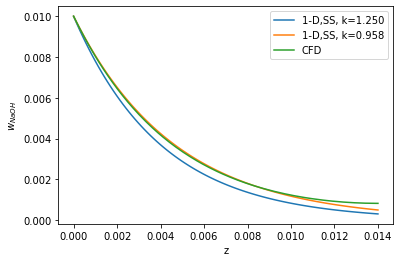

In [12]:
# Visualisation
plt.plot(z_1D,c_an(z, c0, k, D ,v), label='1-D,SS, k=%.3f' % k)
plt.plot(z_1D,c_an(z, c0, k_optimized, D ,v), label="1-D,SS, k=%.3f" % k_optimized)
plt.plot(z_CFD, c_CFD, label='CFD')

plt.xlabel('z')
plt.ylabel(r'$w_{NaOH}$')
plt.legend()